<a href="https://colab.research.google.com/github/APenn215/MSBD-566-Predictive-Modeling/blob/main/Assignment_2_Validation%2C_Tuning_and_Honest_Evaluation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [62]:

from google.colab import drive

drive.mount('/content/drive')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


### Part 1: Understand the Data

The goal of this project is to develop a machine learning model that uses voice recordings to predict whether a person has Parkinson's disease. I believe this model would be most useful for researchers who are studying how voice characteristics can help identify Parkinson's disease. Since we have not fully evaluated the model's performance, I would not recommend using it for actual patient diagnosis at this stage. I would use ROC AUC as the primary success metric because it measures how well the model distinguishes between patients with and without Parkinson's disease. I would also examine sensitivity and specificity because missing a patient with Parkinson's disease could delay further evaluation, while false positives could lead to unnecessary testing.



In [63]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

file_path = '/content/drive/MyDrive/MSBD 545 A2/pd_speech_features.csv'

df = pd.read_csv(file_path, header=1)

df.head()

,id,gender,PPE,DFA,RPDE,numPulses,numPeriodsPulses,meanPeriodPulses,stdDevPeriodPulses,locPctJitter,...,tqwt_kurtosisValue_dec_28,tqwt_kurtosisValue_dec_29,tqwt_kurtosisValue_dec_30,tqwt_kurtosisValue_dec_31,tqwt_kurtosisValue_dec_32,tqwt_kurtosisValue_dec_33,tqwt_kurtosisValue_dec_34,tqwt_kurtosisValue_dec_35,tqwt_kurtosisValue_dec_36,class
0,0,1,0.85247,0.71826,0.57227,240,239,0.008064,0.000087,0.00218,...,1.5620,2.6445,3.8686,4.2105,5.1221,4.4625,2.6202,3.0004,18.9405,1
1,0,1,0.76686,0.69481,0.53966,234,233,0.008258,0.000073,0.00195,...,1.5589,3.6107,23.5155,14.1962,11.0261,9.5082,6.5245,6.3431,45.1780,1
2,0,1,0.85083,0.67604,0.58982,232,231,0.008340,0.000060,0.00176,...,1.5643,2.3308,9.4959,10.7458,11.0177,4.8066,2.9199,3.1495,4.7666,1
3,1,0,0.41121,0.79672,0.59257,178,177,0.010858,0.000183,0.00419,...,3.7805,3.5664,5.2558,14.0403,4.2235,4.6857,4.8460,6.2650,4.0603,1
4,1,0,0.32790,0.79782,0.53028,236,235,0.008162,0.002669,0.00535,...,6.1727,5.8416,6.0805,5.7621,7.7817,11.6891,8.2103,5.0559,6.1164,1


In [64]:
#check the number of recordings and col
print("Data shap:", df.shape)

Data shap: (756, 755)


In [65]:
#Amount of unique aubjects
print("Number of subjects:", df["id"].nunique())

Number of subjects: 252


In [66]:
# number of recordings for each subject
print("\nRecording per subject:")
print(df.groupby("id").size().value_counts().sort_index())


Recording per subject:
3    252
Name: count, dtype: int64


In [67]:
#Class imbalance
#count recordings in each class

print ("Class counts:")
print(df["class"].value_counts())

#Cal the % of recording in each class
print("\nClass precentages:")
print(df["class"].value_counts(normalize=True)* 100)

Class counts:
class
1    564
0    192
Name: count, dtype: int64

Class precentages:
class
1    74.603175
0    25.396825
Name: proportion, dtype: float64


In [68]:

# The majority-class baseline  minimum
# accuracy benchmark for our future model.
majority_class = df["class"].value_counts().idxmax()

baseline_accuracy = (df["class"] == majority_class).mean()

print(f"Majority class: {majority_class}")
print(f"Baseline accuracy: {baseline_accuracy:.3f}")


Majority class: 1
Baseline accuracy: 0.746


In [69]:
# Missing Values ?
missing_values = df.isnull().sum().sum()

#Identical rows
duplicate_rows = df.duplicated().sum()

print("Total missing values:", missing_values)
print("Total identical rows:", duplicate_rows)

Total missing values: 0
Total identical rows: 1


In [70]:
#show sup rows

duplicates = df[df.duplicated(keep=False)]

print(duplicates[["id", "gender", "class"]])
# confim

print("\nNumber of rows involved:", len(duplicates))

     id  gender  class
111  37       0      1
113  37       0      1

Number of rows involved: 2


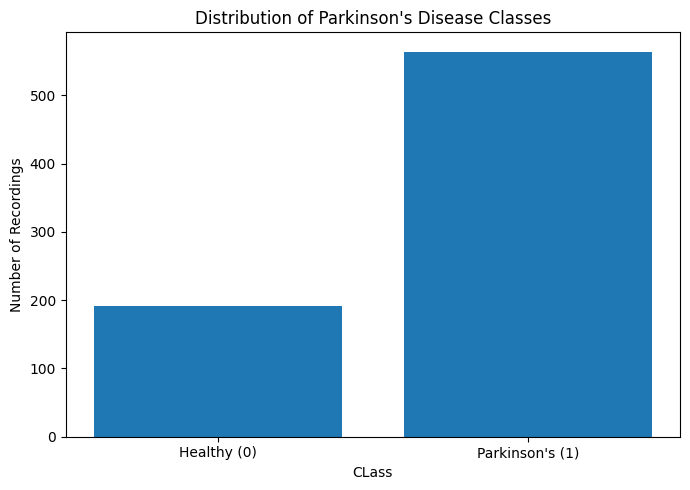

In [71]:
#Creating Chart
class_count =df["class"].value_counts().sort_index()

plt.figure(figsize=(7,5))
plt.bar(
    ["Healthy (0)", "Parkinson's (1)"], class_count.values
)

plt.title("Distribution of Parkinson's Disease Classes")
plt.xlabel("CLass")
plt.ylabel("Number of Recordings")

plt.tight_layout()
plt.show()

**Q1. What is the unit of observation here, and what is the unit of independence? What does that imply for how you may split the data?**

 The unit of observation is each individual voice recording, while the unit of independence is each patient. Each patient has three recordings, randomly splitting the data could place recordings from the same person in both the training and testing sets. This could result in data leakage and make the models performance appear better than it actually is. To avoid this we should spit the data by subject so that all recordings from the same patient stay together.


**Q2. What accuracy does the majority-class baseline get? Which metrics will you report instead, and why? Name the modeling decision your visualization motivates.**

The majority-class baseline accuracy is 0.746 (74.603%), since 564 out of 756 recordings belong to patients with Parkinson's disease. This shows why accuracy alone can be misleading, because a model could predict Parkinson's disease for everyone and still achieve a relatively high score. I would focus on ROC AUC, sensitivity, and specificity to better understand how well the model distinguishes between healthy patients and patients with Parkinson's disease. Since this is a screening tool, I would prioritize sensitivity because missing someone who actually has Parkinson's disease could delay further testing and treatment


**Part 2 — Splitting and Leakage**

In [72]:
#Predictors, outcome and subject

x = df.drop(columns=["id", "class"])
y = df["class"]
groups = df["id"]

print("Predictor shape:", x.shape)
print("Target shape:", y.shape)
print("Number of subjects:", groups.nunique())

Predictor shape: (756, 753)
Target shape: (756,)
Number of subjects: 252


In [73]:
#Spliting the dataset

from sklearn.model_selection import train_test_split

#1 diagnosis for each subject
subject_labels = df.groupby("id")["class"].first()
subject_ids = subject_labels.index

# hold 20%
train_ids, test_ids = train_test_split(
    subject_ids,
    test_size=0.20,
    stratify=subject_labels,
    random_state=42
)

#selecting recordings for each subject group
train_mask = groups.isin(train_ids)
test_mask = groups.isin(test_ids)

X_train = x.loc[train_mask]
X_test = x.loc[test_mask]

y_train = y.loc[train_mask]
y_test = y.loc[test_mask]

groups_train = groups.loc[train_mask]
groups_test = groups.loc[test_mask]

print("Training recordings:", len(X_train))
print("Testing recordings:", len(X_test))

print("Training subjects:", groups_train.nunique())
print("Testing subjects:", groups_test.nunique())

Training recordings: 603
Testing recordings: 153
Training subjects: 201
Testing subjects: 51


In [74]:
#checking for overlap

overlap = set(groups_train).intersection(set(groups_test))

print("Overlapping:", len(overlap))
print("\nTesting class proportions:")
print(y_test.value_counts(normalize=True).sort_index().round(3))


Overlapping: 0

Testing class proportions:
class
0    0.255
1    0.745
Name: proportion, dtype: float64


### **Prediction: StratifiedKFold vs. StratifiedGroupKFold**

I predict that StratifiedKFold will produce a higher ROC AUC because recordings from the same patient could appear in both the training and validation folds. This could make the model perform better because it has already learned characteristics of that patient's voice. However, I believe StratifiedGroupKFold is the better choice because it keeps each patient's recordings together and provides a more trustworthy estimate of how the model performs on new patients.

In [75]:

from sklearn.model_selection import StratifiedKFold, StratifiedGroupKFold

# StratifiedKFold

skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# StratifiedGroupKFold
sgkf = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

print("Cross-validation complete")


Cross-validation complete


In [76]:

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression


log_reg = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        max_iter=5000,
        random_state=42
    ))
])

print("Logistic regression pipeline created ")


Logistic regression pipeline created 


In [77]:
#comparing the cross_validation


from sklearn.model_selection import cross_val_score

# StratifiedKFold
skf_scores = cross_val_score(
    log_reg,
    X_train,
    y_train,
    cv=skf,
    scoring="roc_auc"
)

# StratifiedGroupKFold
sgkf_scores = cross_val_score(
    log_reg,
    X_train,
    y_train,
    groups=groups_train,
    cv=sgkf,
    scoring="roc_auc"
)

print("Logistic Regression Results")


print(f"StratifiedKFold Mean AUC: {skf_scores.mean():.3f}")
print(f"StratifiedGroupKFold Mean AUC: {sgkf_scores.mean():.3f}")


Logistic Regression Results
StratifiedKFold Mean AUC: 0.878
StratifiedGroupKFold Mean AUC: 0.816


In [78]:
#Randpm Forest Model

from sklearn.ensemble import RandomForestClassifier
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

print("Random Forest model created")


Random Forest model created


In [79]:

from sklearn.model_selection import cross_val_score

#recording-level
rf_skf_scores = cross_val_score(
    rf_model,
    X_train,
    y_train,
    cv=skf,
    scoring="roc_auc",
    n_jobs=-1
)

# Subject-level
rf_sgkf_scores = cross_val_score(
    rf_model,
    X_train,
    y_train,
    groups=groups_train,
    cv=sgkf,
    scoring="roc_auc",
    n_jobs=-1
)

print("Random Forest Results")

print(f"StratifiedKFold Mean AUC: {rf_skf_scores.mean():.3f}")
print(f"StratifiedGroupKFold Mean AUC: {rf_sgkf_scores.mean():.3f}")


Random Forest Results
StratifiedKFold Mean AUC: 0.953
StratifiedGroupKFold Mean AUC: 0.857


**Q3. Report all four AUCs. Explain why the two splitters disagree. Which estimate would you report, and what goes wrong if you report the other?**

Logistic regression produced an AUC of 0.878 with StratifiedKFold and 0.816 with StratifiedGroupKFold, while random forest produced 0.953 and 0.857. The scores are different because StratifiedKFold can place recordings from the same patient in both training and validation, which may cause data leakage and make the model appear more accurate. StratifiedGroupKFold keeps each patient's recordings together, preventing this overlap. I would report the grouped AUC scores because they provide a more trustworthy estimate of performance on new patients, while reporting the higher scores could give researchers unrealistic expectations.

**Q4. Why use StratifiedGroupKFold rather than GroupKFold? Would leave-one-out cross-validation be valid?**

StratifiedGroupKFold is a better choice because our dataset contains 252 subjects, with 188 having Parkinson's disease and only 64 being healthy. While both methods keep recordings from the same patient together, StratifiedGroupKFold also helps maintain similar class proportions across folds, making the evaluation more reliable. Regular leave-one-out cross-validation would not be appropriate because recordings from the same patient could appear in both training and validation. Instead, we could use leave-one-subject-out cross-validation, where all three recordings from one patient are held out together. Since each held-out subject belongs to only one class, we would need to combine predictions across subjects to calculate ROC AUC.

In [80]:
#Q5

fold_results = []
for k in [3, 5, 10]:
  cv = StratifiedGroupKFold(
      n_splits=k,
      shuffle=True,
      random_state=42
  )

  scores = cross_val_score(
        log_reg,
        X_train,
        y_train,
        groups=groups_train,
        cv=cv,
        scoring="roc_auc"
    )
  fold_results.append({
        "Folds": k,
        "Mean AUC": scores.mean(),
        "Standard Deviation": scores.std()
    })

results_df = pd.DataFrame(fold_results)
print(results_df.round(3))

   Folds  Mean AUC  Standard Deviation
0      3     0.832               0.048
1      5     0.816               0.070
2     10     0.800               0.066


**Q5. Compare the mean AUC and standard deviation for 3, 5, and 10 folds. Explain the trade-offs.**

Using StratifiedGroupKFold, logistic regression produced a mean AUC of 0.832 with 3 folds, 0.816 with 5 folds, and 0.800 with 10 folds. The standard deviations were 0.048, 0.070, and 0.066, respectively. Although 3 folds produced the highest AUC and lowest standard deviation in this experiment, I would not automatically choose it because each iteration uses less data for training. Increasing the number of folds allows the model to train on more data, but it also creates smaller validation groups, which may lead to less stable results. I would consider 5 folds a reasonable balance between training data, validation size, and computational cost.

# **Part 3**

In [81]:
#Adding Random Features


import numpy as np
import pandas as pd


rng = np.random.default_rng(42)

noise = rng.normal(
    size=(X_train.shape[0], 500)
)

# Give the random features column names
noise_columns = [f"noise_{i}" for i in range(500)]

noise_df = pd.DataFrame(
    noise,
    columns=noise_columns,
    index=X_train.index
)

# Combine t
X_train_noise = pd.concat([X_train, noise_df], axis=1)

print("Original training shape:", X_train.shape)
print("Training shape with noise:", X_train_noise.shape)


Original training shape: (603, 753)
Training shape with noise: (603, 1253)


In [82]:

from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.model_selection import cross_val_score


selector = SelectKBest(score_func=f_classif, k=20)

X_selected_leaky = selector.fit_transform(
    X_train_noise,
    y_train
)

# Evaluate logistic regression
leaky_scores = cross_val_score(
    log_reg,
    X_selected_leaky,
    y_train,
    groups=groups_train,
    cv=sgkf,
    scoring="roc_auc"
)

print("Selected feature shape:", X_selected_leaky.shape)
print(f"Leaky CV Mean AUC: {leaky_scores.mean():.3f}")
print(f"Leaky CV Standard Deviation: {leaky_scores.std():.3f}")


Selected feature shape: (603, 20)
Leaky CV Mean AUC: 0.841
Leaky CV Standard Deviation: 0.032


In [83]:

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.feature_selection import SelectKBest, f_classif


correct_pipeline = Pipeline([
    ("selector", SelectKBest(score_func=f_classif, k=20)),
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=5000, random_state=42))
])

correct_scores = cross_val_score(
    correct_pipeline,
    X_train_noise,
    y_train,
    groups=groups_train,
    cv=sgkf,
    scoring="roc_auc"
)

print(f"Correct CV Mean AUC: {correct_scores.mean():.3f}")
print(f"Correct CV Standard Deviation: {correct_scores.std():.3f}")
print(f"Difference (Leaky - Correct): {leaky_scores.mean() - correct_scores.mean():.3f}")


Correct CV Mean AUC: 0.801
Correct CV Standard Deviation: 0.070
Difference (Leaky - Correct): 0.041


**Q6. Explain the effect of feature-selection leakage on model performance.**

When I selected the 20 best features before cross-validation, the model produced a mean ROC AUC of 0.841 with a standard deviation of 0.032. After moving feature selection inside the pipeline, the mean AUC decreased to 0.801 with a standard deviation of 0.070. The first approach caused data leakage because the validation data influenced which features were selected before the model was evaluated. I would trust the 0.801 AUC more because feature selection was performed using only the training folds, providing a more realistic estimate of performance on unseen patients.

In [84]:

# without the 500 noise
real_feature_scores = cross_val_score(
    correct_pipeline,
    X_train,
    y_train,
    groups=groups_train,
    cv=sgkf,
    scoring="roc_auc"
)

print(f"Original Features Mean AUC: {real_feature_scores.mean():.3f}")
print(f"Original Features Standard Deviation: {real_feature_scores.std():.3f}")
print(f"With Noise Mean AUC: {correct_scores.mean():.3f}")


Original Features Mean AUC: 0.801
Original Features Standard Deviation: 0.070
With Noise Mean AUC: 0.801


In [85]:

# Fit the pipeline on the training data with noise
correct_pipeline.fit(X_train_noise, y_train)

# Get the names
selected_features = X_train_noise.columns[
    correct_pipeline.named_steps["selector"].get_support()
]

# Count how many selected features were random noise
noise_selected = sum(
    feature.startswith("noise_") for feature in selected_features
)

print("Number of noise features selected:", noise_selected)
print("Selected features:")
print(selected_features.tolist())


Number of noise features selected: 0
Selected features:
['mean_MFCC_2nd_coef', 'std_6th_delta_delta', 'std_7th_delta_delta', 'std_8th_delta_delta', 'std_9th_delta_delta', 'tqwt_entropy_shannon_dec_11', 'tqwt_entropy_log_dec_11', 'tqwt_entropy_log_dec_12', 'tqwt_TKEO_std_dec_11', 'tqwt_stdValue_dec_10', 'tqwt_stdValue_dec_11', 'tqwt_stdValue_dec_12', 'tqwt_stdValue_dec_13', 'tqwt_minValue_dec_10', 'tqwt_minValue_dec_11', 'tqwt_minValue_dec_12', 'tqwt_minValue_dec_13', 'tqwt_maxValue_dec_11', 'tqwt_maxValue_dec_12', 'tqwt_maxValue_dec_13']


**Q7. Explain what happened when the random noise features were removed.**

After removing the 500 random features, the model's mean ROC AUC remained at 0.801, with a standard deviation of 0.070. This suggests that the random features did not meaningfully affect the model's performance. When I examined the feature selection results using the full training dataset, SelectKBest selected 20 original voice features and no random noise features. This helps explain why removing the random features did not change the results, although feature selection may vary between cross-validation folds.

# Part **4**

In [86]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score
from sklearn.metrics import roc_auc_score
import numpy as np
import pandas as pd

# Test C values weak
C_values = np.logspace(-5, 1, 10)

results = []

for C in C_values:
    model = Pipeline([
        ("scaler", StandardScaler()),
        ("logistic", LogisticRegression(
            C=C,
            penalty="l2",
            max_iter=5000,
            random_state=42
        ))
    ])

    # Evaluate on training data
    model.fit(X_train, y_train)
    train_auc = roc_auc_score(
        y_train,
        model.predict_proba(X_train)[:, 1]
    )

    # Evaluate on unseen subjects using grouped CV
    cv_scores = cross_val_score(
        model,
        X_train,
        y_train,
        groups=groups_train,
        cv=sgkf,
        scoring="roc_auc"
    )

    results.append({
        "C": C,
        "Train AUC": train_auc,
        "CV AUC": cv_scores.mean()
    })

regularization_results = pd.DataFrame(results)

print(regularization_results.round(3))

        C  Train AUC  CV AUC
0   0.000      0.843   0.820
1   0.000      0.851   0.824
2   0.000      0.873   0.834
3   0.001      0.915   0.850
4   0.005      0.967   0.857
5   0.022      0.996   0.847
6   0.100      1.000   0.830
7   0.464      1.000   0.819
8   2.154      1.000   0.814
9  10.000      1.000   0.805


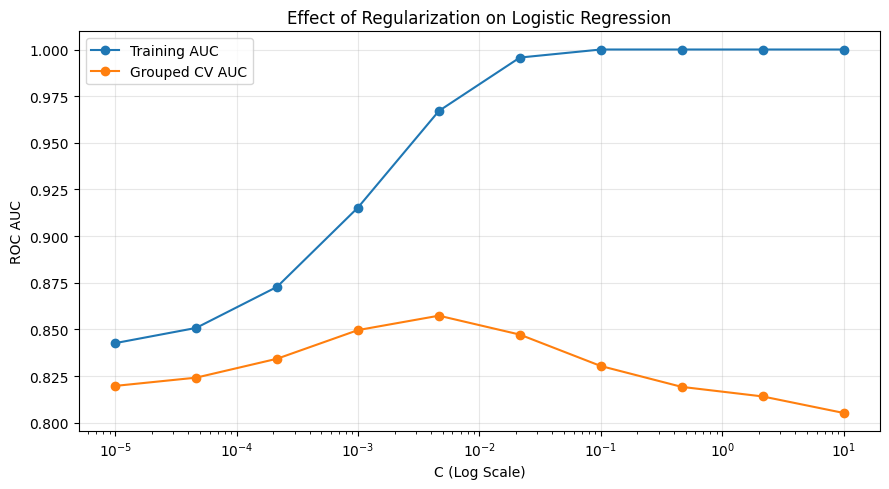

In [87]:

import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.semilogx(
    regularization_results["C"],
    regularization_results["Train AUC"],
    marker="o",
    label="Training AUC"
)

plt.semilogx(
    regularization_results["C"],
    regularization_results["CV AUC"],
    marker="o",
    label="Grouped CV AUC"
)

plt.xlabel("C (Log Scale)")
plt.ylabel("ROC AUC")
plt.title("Effect of Regularization on Logistic Regression")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


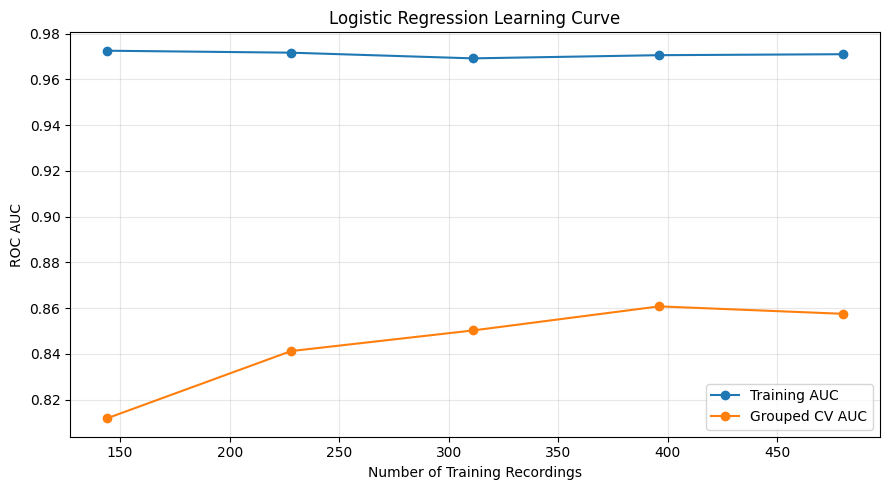

Training sizes: [144 228 311 396 480]
Training AUC: [0.973 0.972 0.969 0.971 0.971]
Validation AUC: [0.812 0.841 0.85  0.861 0.858]


In [88]:

from sklearn.model_selection import learning_curve
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
import numpy as np
import matplotlib.pyplot as plt

# Use the best C value
best_C = regularization_results.loc[
    regularization_results["CV AUC"].idxmax(), "C"
]

learning_model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        C=best_C,
        penalty="l2",
        max_iter=5000,
        random_state=42
    ))
])

# training and validation performance
train_sizes, train_scores, val_scores = learning_curve(
    learning_model,
    X_train,
    y_train,
    groups=groups_train,
    cv=sgkf,
    scoring="roc_auc",
    train_sizes=np.linspace(0.3, 1.0, 5),
    shuffle=True,
    random_state=42
)

#  AUC across folds
train_mean = train_scores.mean(axis=1)
val_mean = val_scores.mean(axis=1)

# Plot learning curve
plt.figure(figsize=(9, 5))

plt.plot(
    train_sizes, train_mean,
    marker="o", label="Training AUC"
)

plt.plot(
    train_sizes, val_mean,
    marker="o", label="Grouped CV AUC"
)

plt.xlabel("Number of Training Recordings")
plt.ylabel("ROC AUC")
plt.title("Logistic Regression Learning Curve")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("Training sizes:", train_sizes)
print("Training AUC:", np.round(train_mean, 3))
print("Validation AUC:", np.round(val_mean, 3))


In [89]:

from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import cross_val_score
import numpy as np
import pandas as pd

# Use the C value that performed best i
best_C = regularization_results.loc[
    regularization_results["CV AUC"].idxmax(), "C"
]

penalties = [
    ("L1", "l1", None),
    ("L2", "l2", None),
    ("Elastic Net", "elasticnet", 0.5)
]

penalty_results = []

for name, penalty, l1_ratio in penalties:

    model = Pipeline([
        ("scaler", StandardScaler()),
        ("logistic", LogisticRegression(
            penalty=penalty,
            C=best_C,
            solver="saga",
            l1_ratio=l1_ratio,
            max_iter=10000,
            random_state=42
        ))
    ])

    # Evaluate performance
    scores = cross_val_score(
        model,
        X_train,
        y_train,
        groups=groups_train,
        cv=sgkf,
        scoring="roc_auc"
    )

    # Fit
    model.fit(X_train, y_train)

    coefficients = model.named_steps["logistic"].coef_[0]
    nonzero = np.sum(np.abs(coefficients) > 1e-6)

    penalty_results.append({
        "Penalty": name,
        "Mean AUC": scores.mean(),
        "Standard Deviation": scores.std(),
        "Nonzero Coefficients": nonzero
    })

penalty_df = pd.DataFrame(penalty_results)
print(penalty_df.round(3))


       Penalty  Mean AUC  Standard Deviation  Nonzero Coefficients
0           L1     0.500               0.000                     0
1           L2     0.857               0.067                   753
2  Elastic Net     0.500               0.000                     2


**Q8. Regularization and Learning Curve**

The regularization experiment showed that logistic regression performed best at C = 0.00464, with a grouped validation AUC of 0.857. As C increased, training performance improved, but validation performance eventually decreased, suggesting overfitting. At C = 10, the training AUC reached 1.000 while the validation AUC dropped to 0.805. The learning curve also showed that validation AUC generally improved from 0.812 to 0.858 as training recordings increased from 144 to 480, suggesting that additional patient data could help improve generalization. However, the remaining gap between training and validation performance indicates that some overfitting may still be present.

In [90]:

# Fit the L2 model
l2_model = Pipeline([
    ("scaler", StandardScaler()),
    ("logistic", LogisticRegression(
        penalty="l2",
        C=best_C,
        solver="saga",
        max_iter=10000,
        random_state=42
    ))
])

l2_model.fit(X_train, y_train)

# Extract coefficients
coefs = l2_model.named_steps["logistic"].coef_[0]

coef_df = pd.DataFrame({
    "Feature": X_train.columns,
    "Coefficient": coefs,
    "Odds Ratio": np.exp(coefs)
})

# Find the three largest coefficients
top3 = coef_df.reindex(
    coef_df["Coefficient"].abs().sort_values(ascending=False).index
).head(3)

print(top3.round(3))


                     Feature  Coefficient  Odds Ratio
572    tqwt_meanValue_dec_36       -0.095       0.909
72            mean_2nd_delta       -0.082       0.922
536  tqwt_medianValue_dec_36       -0.078       0.925


**Q9. Compare L1, L2, and Elastic Net regularization and interpret the L2 coefficients.**

L2 regularization performed best, with a mean ROC AUC of 0.857 and all 753 coefficients remaining nonzero. L1 produced an AUC of 0.500 with no nonzero coefficients, while Elastic Net also produced an AUC of 0.500 and retained only two coefficients, suggesting that the selected regularization strength was too strong for these methods. The three largest L2 coefficients by absolute value were tqwt_meanValue_dec_36 (-0.095), mean_2nd_delta (-0.082), and tqwt_medianValue_dec_36 (-0.078). Their odds ratios were 0.909, 0.922, and 0.925, indicating that a one-standard-deviation increase in each feature was associated with approximately 9.1%, 7.8%, and 7.5% lower modeled odds of Parkinson's disease, respectively, when holding the other features constant. These results show that L2 provided better predictive performance at the tested C value, while the coefficient interpretations describe associations rather than causal relationships.

# **Part 5**

In [91]:

import time
import numpy as np
import pandas as pd
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.model_selection import (
    cross_val_score, GridSearchCV, RandomizedSearchCV,
    StratifiedGroupKFold
)
from sklearn.experimental import enable_halving_search_cv
from sklearn.model_selection import HalvingRandomSearchCV

models = {
    "Logistic Regression": Pipeline([
        ("scale", StandardScaler()),
        ("model", LogisticRegression(C=best_C, max_iter=5000,
                                     random_state=42))
    ]),
    "Random Forest": RandomForestClassifier(
        n_estimators=100, random_state=42, n_jobs=-1
    ),
    "SVM": Pipeline([
        ("scale", StandardScaler()),
        ("model", SVC(kernel="rbf", probability=True,
                      random_state=42))
    ])
}

# Compare model families
comparison = []
for name, model in models.items():
    scores = cross_val_score(
        model, X_train, y_train, groups=groups_train,
        cv=sgkf, scoring="roc_auc", n_jobs=-1
    )
    comparison.append({
        "Model": name, "Mean AUC": scores.mean(),
        "SD": scores.std()
    })

comparison_df = pd.DataFrame(comparison)
print("MODEL COMPARISON")
print(comparison_df.round(3))

# Three tuning approaches for logistic regression
base_model = Pipeline([
    ("scale", StandardScaler()),
    ("model", LogisticRegression(max_iter=5000, random_state=42))
])
param_grid = {"model__C": [0.0001, 0.001, 0.01, 0.1, 1]}

searches = {
    "Grid": GridSearchCV(
        base_model, param_grid, cv=sgkf, scoring="roc_auc", n_jobs=-1
    ),
    "Random": RandomizedSearchCV(
        base_model, param_grid, n_iter=3, cv=sgkf,
        scoring="roc_auc", random_state=42, n_jobs=-1
    ),
    "Halving": HalvingRandomSearchCV(
        base_model, param_grid, n_candidates=5,
        resource="n_samples", min_resources=150,
        cv=sgkf, scoring="roc_auc", random_state=42,
        n_jobs=-1
    )
}

search_results = []
for name, search in searches.items():
    start = time.time()
    search.fit(X_train, y_train, groups=groups_train)
    search_results.append({
        "Search": name,
        "Best CV AUC": search.best_score_,
        "Best Params": search.best_params_,
        "Seconds": time.time() - start
    })

search_df = pd.DataFrame(search_results)
print("\nSEARCH COMPARISON")
print(search_df.round(3))

# Nested grouped cross-validation
outer_cv = StratifiedGroupKFold(
    n_splits=5, shuffle=True, random_state=42
)
nested_results = []

for fold, (tr, val) in enumerate(
    outer_cv.split(X_train, y_train, groups_train), 1
):
    inner_cv = StratifiedGroupKFold(
        n_splits=3, shuffle=True, random_state=42
    )
    search = GridSearchCV(
        base_model, param_grid, cv=inner_cv,
        scoring="roc_auc", n_jobs=-1
    )
    search.fit(
        X_train.iloc[tr], y_train.iloc[tr],
        groups=groups_train.iloc[tr]
    )
    from sklearn.metrics import roc_auc_score
    probabilities = search.best_estimator_.predict_proba(
        X_train.iloc[val]
    )[:, 1]
    nested_results.append({
        "Fold": fold,
        "Outer AUC": roc_auc_score(y_train.iloc[val], probabilities),
        "Best C": search.best_params_["model__C"]
    })

nested_df = pd.DataFrame(nested_results)
print("\nNESTED CROSS-VALIDATION")
print(nested_df.round(3))
print("Nested mean AUC:", round(nested_df["Outer AUC"].mean(), 3))
print("Nested SD:", round(nested_df["Outer AUC"].std(), 3))


MODEL COMPARISON
                 Model  Mean AUC     SD
0  Logistic Regression     0.857  0.066
1        Random Forest     0.857  0.052
2                  SVM     0.831  0.069

SEARCH COMPARISON
    Search  Best CV AUC          Best Params  Seconds
0     Grid        0.857   {'model__C': 0.01}    1.342
1   Random        0.857   {'model__C': 0.01}    0.963
2  Halving        0.838  {'model__C': 0.001}    1.767

NESTED CROSS-VALIDATION
   Fold  Outer AUC  Best C
0     1      0.764   0.010
1     2      0.936   0.001
2     3      0.870   0.000
3     4      0.839   0.001
4     5      0.791   0.001
Nested mean AUC: 0.84
Nested SD: 0.068


# **Q10**

Logistic regression and Random Forest both achieved a mean grouped ROC AUC of 0.857, while SVM achieved 0.831. Although logistic regression and Random Forest performed equally well on average, logistic regression had a slightly higher standard deviation (0.066 compared with 0.052). These results suggest that both models are reasonable choices, but logistic regression offers an advantage in interpretability. I would choose logistic regression for further evaluation because it performed well and allows us to examine how individual voice features contribute to predictions.

# **Q11**
GridSearchCV and RandomizedSearchCV both selected C = 0.01 and achieved a best cross-validation AUC of 0.857. RandomizedSearchCV was slightly faster at 0.989 seconds compared with 1.338 seconds for GridSearchCV. HalvingRandomSearchCV selected C = 0.001 and achieved a lower AUC of 0.838, taking 2.227 seconds. In this experiment, randomized search was the fastest, although the methods evaluated different numbers of candidates and resources, so their runtimes are not directly equivalent.

# **Q12**
Nested cross-validation produced a mean outer-fold ROC AUC of 0.840 with a standard deviation of 0.068, compared with the non-nested best cross-validation score of 0.857. The outer-fold AUC values ranged from 0.764 to 0.936, showing that performance varied across groups of subjects. The best C value also changed across folds, suggesting that the optimal regularization strength depends partly on the training subjects. Nested cross-validation provides a more honest estimate because hyperparameter selection occurs within the inner folds, while the outer folds evaluate the selected model on subjects not used during tuning.

## **Part 6 Final evaluation**

CLASS WEIGHT COMPARISON
     Weight  OOF AUC  OOF AP
0   Default    0.837   0.930
1  Balanced    0.834   0.929

CHOSEN WEIGHT: Default
CHOSEN THRESHOLD: 0.4
    Threshold  Sensitivity  Specificity
0        0.20        0.984        0.288
1        0.25        0.980        0.320
2        0.30        0.971        0.386
3        0.35        0.962        0.471
4        0.40        0.960        0.510
5        0.45        0.947        0.569
6        0.50        0.931        0.614
7        0.55        0.916        0.641
8        0.60        0.891        0.660
9        0.65        0.862        0.667
10       0.70        0.820        0.706
11       0.75        0.771        0.732
12       0.80        0.720        0.765

FINAL TEST RESULTS
ROC AUC: 0.819
Average Precision: 0.934
Sensitivity: 0.939
Precision: 0.811
Brier Score: 0.148
Confusion Matrix:
 [[ 14  25]
 [  7 107]]


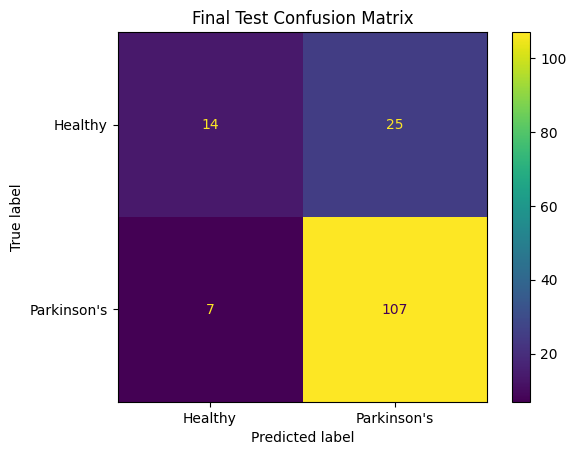

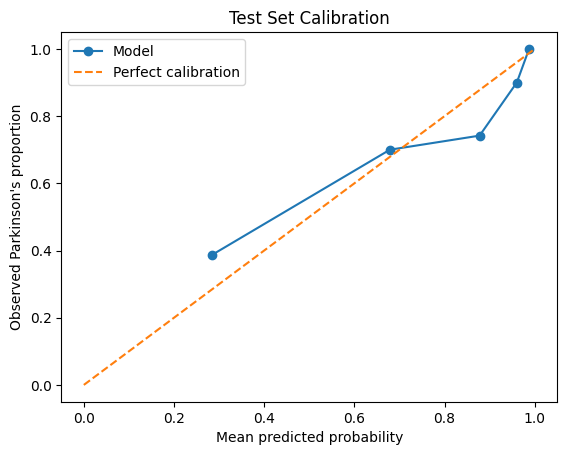

95% Subject Bootstrap AUC CI: 0.697 to 0.92


In [92]:

from sklearn.model_selection import cross_val_predict
from sklearn.metrics import (
    roc_auc_score, average_precision_score,
    confusion_matrix, recall_score, precision_score,
    brier_score_loss, ConfusionMatrixDisplay
)
from sklearn.calibration import calibration_curve
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Compare class weights using grouped training CV only
weight_results = []
oof_predictions = {}

for weight_name, weight in [
    ("Default", None),
    ("Balanced", "balanced")
]:
    candidate = Pipeline([
        ("scale", StandardScaler()),
        ("model", LogisticRegression(
            C=0.01, class_weight=weight,
            max_iter=5000, random_state=42
        ))
    ])

    probabilities = cross_val_predict(
        candidate, X_train, y_train,
        groups=groups_train, cv=sgkf,
        method="predict_proba", n_jobs=-1
    )[:, 1]

    oof_predictions[weight_name] = probabilities

    weight_results.append({
        "Weight": weight_name,
        "OOF AUC": roc_auc_score(y_train, probabilities),
        "OOF AP": average_precision_score(y_train, probabilities)
    })

print("CLASS WEIGHT COMPARISON")
print(pd.DataFrame(weight_results).round(3))

# Choose class weighting based on training-only OOF AUC
weight_table = pd.DataFrame(weight_results)
chosen_name = weight_table.loc[
    weight_table["OOF AUC"].idxmax(), "Weight"
]
chosen_weight = None if chosen_name == "Default" else "balanced"
train_probs = oof_predictions[chosen_name]

# Select threshold to prioritize sensitivity while maintaining
# at least 50% specificity on training predictions
threshold_results = []
for threshold in np.arange(0.20, 0.81, 0.05):
    predictions = (train_probs >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(
        y_train, predictions, labels=[0, 1]
    ).ravel()
    sensitivity = tp / (tp + fn)
    specificity = tn / (tn + fp)
    threshold_results.append({
        "Threshold": threshold,
        "Sensitivity": sensitivity,
        "Specificity": specificity
    })

threshold_df = pd.DataFrame(threshold_results)
eligible = threshold_df[threshold_df["Specificity"] >= 0.50]

if len(eligible):
    chosen_threshold = eligible.sort_values(
        ["Sensitivity", "Specificity"],
        ascending=False
    ).iloc[0]["Threshold"]
else:
    chosen_threshold = 0.50

print("\nCHOSEN WEIGHT:", chosen_name)
print("CHOSEN THRESHOLD:", round(chosen_threshold, 3))
print(threshold_df.round(3))

# Fit on all training data, then evaluate test data ONCE
final_model = Pipeline([
    ("scale", StandardScaler()),
    ("model", LogisticRegression(
        C=0.01, class_weight=chosen_weight,
        max_iter=5000, random_state=42
    ))
])
final_model.fit(X_train, y_train)

test_probs = final_model.predict_proba(X_test)[:, 1]
test_preds = (test_probs >= chosen_threshold).astype(int)

test_auc = roc_auc_score(y_test, test_probs)
test_ap = average_precision_score(y_test, test_probs)
test_cm = confusion_matrix(y_test, test_preds, labels=[0, 1])

print("\nFINAL TEST RESULTS")
print("ROC AUC:", round(test_auc, 3))
print("Average Precision:", round(test_ap, 3))
print("Sensitivity:", round(recall_score(y_test, test_preds), 3))
print("Precision:", round(precision_score(y_test, test_preds), 3))
print("Brier Score:", round(brier_score_loss(y_test, test_probs), 3))
print("Confusion Matrix:\n", test_cm)

ConfusionMatrixDisplay(
    confusion_matrix=test_cm,
    display_labels=["Healthy", "Parkinson's"]
).plot()
plt.title("Final Test Confusion Matrix")
plt.show()

# Calibration plot
fraction_positive, mean_predicted = calibration_curve(
    y_test, test_probs, n_bins=5, strategy="quantile"
)
plt.plot(mean_predicted, fraction_positive, "o-", label="Model")
plt.plot([0, 1], [0, 1], "--", label="Perfect calibration")
plt.xlabel("Mean predicted probability")
plt.ylabel("Observed Parkinson's proportion")
plt.title("Test Set Calibration")
plt.legend()
plt.show()

# 95% bootstrap confidence interval resampling entire subjects
rng = np.random.default_rng(42)
test_subjects = np.unique(groups_test)
bootstrap_aucs = []

for _ in range(1000):
    sampled_subjects = rng.choice(
        test_subjects, size=len(test_subjects), replace=True
    )
    sampled_indices = np.concatenate([
        np.flatnonzero(groups_test.to_numpy() == subject)
        for subject in sampled_subjects
    ])
    sampled_y = y_test.to_numpy()[sampled_indices]
    sampled_probs = test_probs[sampled_indices]

    if len(np.unique(sampled_y)) == 2:
        bootstrap_aucs.append(
            roc_auc_score(sampled_y, sampled_probs)
        )

ci_low, ci_high = np.percentile(
    bootstrap_aucs, [2.5, 97.5]
)
print("95% Subject Bootstrap AUC CI:",
      round(ci_low, 3), "to", round(ci_high, 3))


# **Q13**
The final model was logistic regression with C = 0.01 and default class weights, which performed slightly better than balanced class weights during training cross-validation (ROC AUC of 0.837 compared with 0.834). I selected a classification threshold of 0.400 using only training predictions to prioritize sensitivity while maintaining at least 50% specificity. On the held-out test set, the model achieved a ROC AUC of 0.819, average precision of 0.934, sensitivity of 0.939, and precision of 0.811. The confusion matrix showed 107 correctly identified Parkinson's recordings, 14 correctly identified healthy recordings, 25 false positives, and 7 false negatives. These results suggest that the model identifies most Parkinson's recordings but incorrectly flags many healthy recordings.

# **Q14**
The final model achieved a Brier score of 0.148, and the calibration plot showed that predicted probabilities were reasonably close to observed outcomes in some ranges but differed in others. The test ROC AUC was 0.819, with a 95% subject-level bootstrap confidence interval of 0.697 to 0.920, indicating uncertainty in how well the model may perform on other subjects. Although the model detected most Parkinson's recordings, it incorrectly classified 25 of the 39 healthy recordings as Parkinson's, resulting in a specificity of approximately 0.359. Because the dataset contains repeated recordings from the same subjects and the model was evaluated on a limited number of people, further validation on independent subjects would be necessary before considering clinical use.